In [26]:
import pandas as pd
from google.colab import drive

# Step 1: connect the notebook to your Google Drive
drive.mount('/content/drive')

# Step 2: store the folder path once so every read uses it
path = '/content/drive/MyDrive/Data for MIS 433/mis433-churn-data/'

# Step 3: read each CSV into its own DataFrame
train = pd.read_csv(path + 'churn_train.csv')
test = pd.read_csv(path + 'churn_test.csv')
accounts = pd.read_csv(path + 'accounts.csv')
demographics = pd.read_csv(path + 'demographics.csv')
services = pd.read_csv(path + 'services.csv')

# Step 4: confirm each file loaded with the expected shape
for name, df in [('train', train), ('test', test), ('accounts', accounts),
                 ('demographics', demographics), ('services', services)]:
    print(name, df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train (4238, 2)
test (1060, 1)
accounts (5298, 8)
demographics (5298, 8)
services (47682, 3)


# Accounts

In [27]:
#Describe accounts df
accounts.head()

,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1203,399.75,5-1-2012,5217.00,10-Jan-11,Yes,Month-to-month,Bank transfer (automatic)
3,1204,324.75,5-1-2012,22757.50,6-Apr-06,No,One year,Bank transfer (automatic)
4,1205,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check


In [28]:
accounts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerNo         5298 non-null   int64  
 1   BaseCharges        5298 non-null   float64
 2   DOC                5298 non-null   object 
 3   TotalCharges       5288 non-null   float64
 4   DOE                5298 non-null   object 
 5   ElectronicBilling  5298 non-null   object 
 6   ContractType       5293 non-null   object 
 7   PaymentMethod      5298 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 331.3+ KB


In [29]:
#Check accounts for missing values
accounts.isna().sum()


,0
CustomerNo,0
BaseCharges,0
DOC,0
TotalCharges,10
DOE,0
ElectronicBilling,0
ContractType,5
PaymentMethod,0


In [30]:
accounts.describe()

,CustomerNo,BaseCharges,TotalCharges
count,5298.000000,5298.000000,5288.000000
mean,3849.500000,325.467205,11928.354056
std,1529.545194,151.352954,11486.453199
min,1201.000000,91.250000,94.250000
25%,2525.250000,178.250000,2314.937500
50%,3849.500000,352.500000,7377.500000
75%,5173.750000,451.250000,19992.812500
max,6498.000000,593.750000,43424.000000


In [31]:
#Count contract types in accounts, including missing values
accounts['ContractType'].value_counts(dropna=False)

,count
ContractType,
Month-to-month,2779
Two year,1364
One year,1150
NaN,5


# Demographics

In [32]:
#Describe demographics df
demographics.head()

,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
0,1201,India,Maharashtra,0,2,2,Masters,Male
1,1202,India,Maharashtra,0,2,2,ProfessionalQalification,Male
2,1203,India,Maharashtra,0,2,2,ProfessionalQalification,Male
3,1204,India,Maharashtra,0,2,1,ProfessionalQalification,Male
4,1205,India,Maharashtra,0,2,2,ProfessionalQalification,Female


In [33]:
demographics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerNo     5298 non-null   int64 
 1   Country        5298 non-null   object
 2   State          5298 non-null   object
 3   Retired        5298 non-null   int64 
 4   HasPartner     5298 non-null   int64 
 5   HasDependents  5298 non-null   int64 
 6   Education      5288 non-null   object
 7   Gender         5294 non-null   object
dtypes: int64(4), object(4)
memory usage: 331.3+ KB


In [34]:
#Check demographics for missing values
demographics.isna().sum()

,0
CustomerNo,0
Country,0
State,0
Retired,0
HasPartner,0
HasDependents,0
Education,10
Gender,4


In [35]:
demographics.describe()

,CustomerNo,Retired,HasPartner,HasDependents
count,5298.000000,5298.000000,5298.000000,5298.000000
mean,3849.500000,0.158362,1.502454,1.690827
std,1529.545194,0.365114,0.500041,0.462196
min,1201.000000,0.000000,1.000000,1.000000
25%,2525.250000,0.000000,1.000000,1.000000
50%,3849.500000,0.000000,2.000000,2.000000
75%,5173.750000,0.000000,2.000000,2.000000
max,6498.000000,1.000000,2.000000,2.000000


In [36]:
#Count categories in demographics text columns
demographics['Country'].value_counts()

,count
Country,
India,5293
?,5


In [37]:
demographics['Education'].value_counts(dropna=False)

,count
Education,
Highschool or below,1426
Graduation,1370
Masters,1265
ProfessionalQalification,1186
Other,41
NaN,10


# Services

In [38]:
#Describe services df
services.head()

,CustomerNo,TypeOfService,SeviceDetails
0,1201,DeviceProtection,Yes
1,1201,HasPhoneService,1
2,1201,InternetServiceCategory,Fiber optic
3,1201,MultipleLines,No
4,1201,OnlineBackup,No


In [39]:
services.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47682 entries, 0 to 47681
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerNo     47682 non-null  int64 
 1   TypeOfService  47682 non-null  object
 2   SeviceDetails  47682 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


In [40]:
#Check services for missing values
services.isna().sum()

,0
CustomerNo,0
TypeOfService,0
SeviceDetails,0


In [41]:
services.describe()

,CustomerNo
count,47682.000000
mean,3849.500000
std,1529.416874
min,1201.000000
25%,2525.000000
50%,3849.500000
75%,5174.000000
max,6498.000000


In [42]:
#See which services exist and what values each can take
services.groupby('TypeOfService')['SeviceDetails'].unique()

,SeviceDetails
TypeOfService,
DeviceProtection,"[Yes, No internet service, No]"
HasPhoneService,"[1, 0]"
InternetServiceCategory,"[Fiber optic, No, DSL]"
MultipleLines,"[No, Yes, No phone service]"
OnlineBackup,"[No, No internet service, Yes]"
OnlineSecurity,"[No, No internet service, Yes]"
StreamingMovies,"[Yes, No internet service, No]"
StreamingTelevision,"[Yes, No internet service, No]"
TechnicalSupport,"[No, No internet service, Yes]"


# Train

In [43]:
#Describe train df
train.head()

,CustomerNo,Churn
0,1201,0
1,1202,0
2,1205,1
3,1206,0
4,1207,0


In [44]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerNo  4238 non-null   int64
 1   Churn       4238 non-null   int64
dtypes: int64(2)
memory usage: 66.3 KB


In [45]:
#Check train for missing values
train.isna().sum()

,0
CustomerNo,0
Churn,0


In [46]:
train.describe()

,CustomerNo,Churn
count,4238.000000,4238.000000
mean,3841.604059,0.247522
std,1535.584457,0.431624
min,1201.000000,0.000000
25%,2506.250000,0.000000
50%,3849.500000,0.000000
75%,5168.750000,0.000000
max,6498.000000,1.000000


In [47]:
#Check the balance of the target variable
train['Churn'].value_counts(normalize=True)

,proportion
Churn,
0,0.752478
1,0.247522


# Merge the Tables
Accounts and demographics have one row per customer, but services has nine rows per customer (one per service type). Before merging, services must be reshaped so it also has one row per customer. This is called going from long format to wide format.

In [48]:
#Reshape services from long (9 rows per customer) to wide (1 row per customer)
#index = what each row represents, columns = which values become the new column names, values = what fills the cells
services_wide = services.pivot(index='CustomerNo', columns='TypeOfService', values='SeviceDetails').reset_index()
services_wide.head()

TypeOfService,CustomerNo,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1203,No,1,Fiber optic,No,No,No,Yes,No,No
3,1204,No,1,DSL,Yes,Yes,Yes,No,No,Yes
4,1205,No,1,Fiber optic,Yes,No,No,No,No,No


In [49]:
#Merge accounts, demographics and services into one customer table, using CustomerNo as the key
#how='left' keeps every row of the left table and attaches the matching columns from the right table
customers = accounts.merge(demographics, on='CustomerNo', how='left').merge(services_wide, on='CustomerNo', how='left')
print(customers.shape)

(5298, 24)


# Preprocessing: Cleaning
The describe step found four problems: dates stored as text, a few missing values, a service column stored as text, and columns that never vary. Each is fixed below.

In [50]:
#Convert the date columns from text to real dates. The format string tells pandas how the text is laid out
#DOE = date the customer enrolled, DOC = date the data was collected (the same day for everyone)
customers['DOE'] = pd.to_datetime(customers['DOE'], format='%d-%b-%y')
customers['DOC'] = pd.to_datetime(customers['DOC'], format='%d-%m-%Y')
#New feature: tenure = how many months the customer has been with the company
customers['TenureMonths'] = (customers['DOC'] - customers['DOE']).dt.days / 30
customers['TenureMonths'].describe()

,TenureMonths
count,5298.000000
mean,33.729332
std,24.604563
min,0.000000
25%,10.000000
50%,31.000000
75%,57.000000
max,72.000000


In [51]:
#TotalCharges is missing only for brand new customers (tenure 0 or 1), so fill it with one month of BaseCharges
customers['TotalCharges'] = customers['TotalCharges'].fillna(customers['BaseCharges'])
#Fill missing categories with the most common value (the mode). mode() returns a Series, so [0] takes the first value
customers['ContractType'] = customers['ContractType'].fillna(customers['ContractType'].mode()[0])
customers['Gender'] = customers['Gender'].fillna(customers['Gender'].mode()[0])
#Missing Education goes into the existing Other group
customers['Education'] = customers['Education'].fillna('Other')
#HasPhoneService came out of the pivot as text ('1' or '0'), so convert it back to a number
customers['HasPhoneService'] = customers['HasPhoneService'].astype(int)
#Drop columns with no predictive value: DOC is one date for everyone, Country and State are nearly constant
customers = customers.drop(columns=['DOC', 'DOE', 'Country', 'State'])
#Confirm no missing values remain (should print 0)
print(customers.isna().sum().sum())

0


# Exploratory Data Analysis
Churn is only known for the training customers, so the charts below use the training set joined to the customer table.

In [52]:
import matplotlib.pyplot as plt  #base charting library
import seaborn as sns  #statistical charts built on matplotlib
#Attach customer information to the training labels so churn can be compared across variables
train_full = train.merge(customers, on='CustomerNo', how='left')
print(train_full.shape)

(4238, 22)


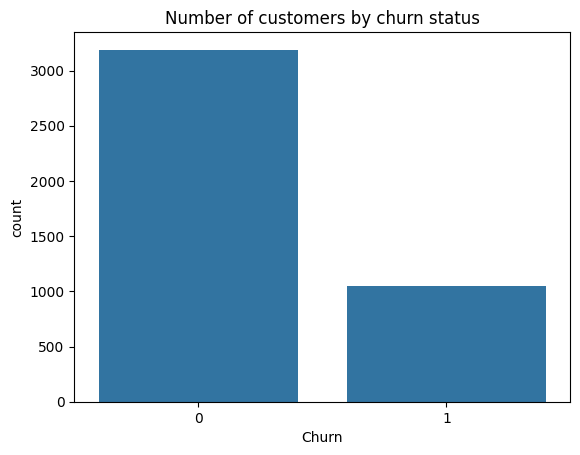

In [53]:
#Chart 1: how many customers churned (1) versus stayed (0)
sns.countplot(data=train_full, x='Churn')
plt.title('Number of customers by churn status')
plt.show()

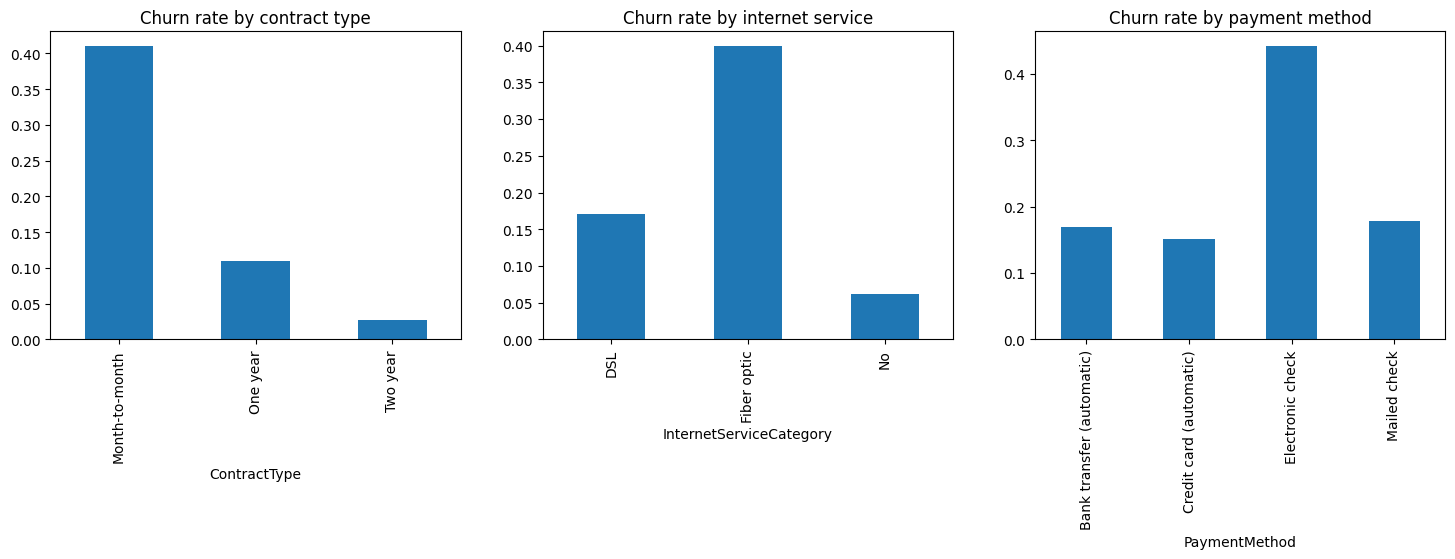

In [54]:
#Chart 2: churn rate by category. Because Churn is 0 or 1, its mean within a group is the churn rate of that group
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
train_full.groupby('ContractType')['Churn'].mean().plot(kind='bar', ax=axes[0], title='Churn rate by contract type')
train_full.groupby('InternetServiceCategory')['Churn'].mean().plot(kind='bar', ax=axes[1], title='Churn rate by internet service')
train_full.groupby('PaymentMethod')['Churn'].mean().plot(kind='bar', ax=axes[2], title='Churn rate by payment method')
plt.show()

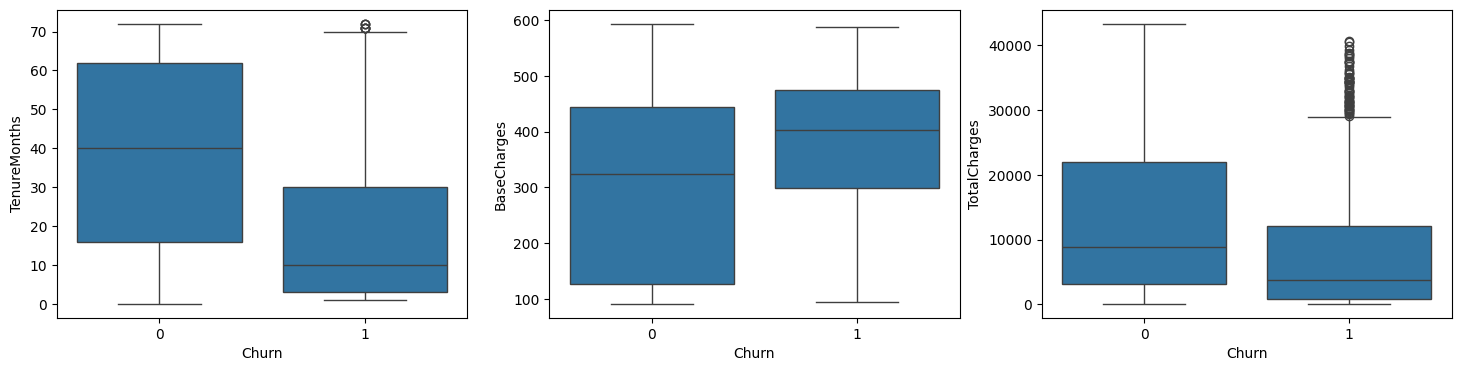

In [55]:
#Chart 3: compare the numeric variables for customers who stayed (0) versus churned (1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.boxplot(data=train_full, x='Churn', y='TenureMonths', ax=axes[0])
sns.boxplot(data=train_full, x='Churn', y='BaseCharges', ax=axes[1])
sns.boxplot(data=train_full, x='Churn', y='TotalCharges', ax=axes[2])
plt.show()

In [56]:
#Summary table: average of each numeric variable for stayed (0) versus churned (1)
train_full.groupby('Churn')[['TenureMonths', 'BaseCharges', 'TotalCharges']].mean().round(1)

,TenureMonths,BaseCharges,TotalCharges
Churn,,,
0,38.6,308.7,13165.0
1,18.7,378.3,8073.9


**What the EDA shows**

Contract type appears to be the strongest signal in the data. About 41% of month-to-month customers churned, compared to 11% on one year contracts and 3% on two year contracts. Internet service also matters, since fiber optic customers churned at about 40% while DSL customers churned at 17% and customers with no internet service churned at 6%. Customers who pay by electronic check churned at about 44%, which is roughly double every other payment method. Finally, the customers who churned tend to be newer and pay more each month, with an average tenure of about 19 months compared to 39 and average base charges of about 378 compared to 309.

# Preprocessing: Encoding and Standardization
Models need numbers, so each text column is converted into 0/1 columns (one-hot encoding). The numeric columns are then standardized so that a variable with large values, such as TotalCharges, does not outweigh a variable with small values.

In [57]:
#One-hot encoding: get_dummies turns each text category into its own 0/1 column
#drop_first=True removes one redundant column per variable (if a customer is not One year or Two year, they must be Month-to-month)
#set_index moves CustomerNo out of the columns so it is used as a row label and not as a feature
features = pd.get_dummies(customers.set_index('CustomerNo'), drop_first=True, dtype=int)
print(features.shape)

(5298, 34)


In [58]:
#Split the features back into training customers and test customers. loc selects rows by their CustomerNo label
X = features.loc[train['CustomerNo']]
y = train['Churn'].to_numpy()
X_test = features.loc[test['CustomerNo']]
print(X.shape, X_test.shape)

(4238, 34) (1060, 34)


In [59]:
from sklearn.model_selection import train_test_split  #splits data into two random parts
from sklearn.preprocessing import StandardScaler  #rescales each column to mean 0 and standard deviation 1
#Hold out 20% of the training data as a validation set to estimate accuracy before using Kaggle
#stratify=y keeps the same churn percentage in both parts, random_state makes the split repeatable
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#Fit the scaler on the training part only, then apply the same scaling to the validation part
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_val_s = scaler.transform(X_val)
print(X_tr_s.shape, X_val_s.shape)

(3390, 34) (848, 34)


# Model Building
Three classification models are trained on the same training part and compared on the same validation part. Accuracy is the share of predictions that are correct, which is the same metric Kaggle uses for this competition.

In [60]:
from sklearn.linear_model import LogisticRegression  #model 1
from sklearn.metrics import accuracy_score  #share of predictions that are correct
#Model 1: Logistic regression. It gives each feature a weight and combines them into a probability of churn
#max_iter=1000 gives the solver enough steps to finish
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_tr_s, y_tr)
acc_logreg = accuracy_score(y_val, logreg.predict(X_val_s))
print('Logistic regression validation accuracy:', round(acc_logreg, 4))

Logistic regression validation accuracy: 0.8361


In [61]:
from sklearn.tree import DecisionTreeClassifier  #model 2
#Model 2: Decision tree. It learns a series of if/then splits on the features
#max_depth=5 limits the tree to 5 levels so it does not memorize the training data (overfitting)
tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_tr_s, y_tr)
acc_tree = accuracy_score(y_val, tree.predict(X_val_s))
print('Decision tree validation accuracy:', round(acc_tree, 4))

Decision tree validation accuracy: 0.8125


In [62]:
from sklearn.ensemble import RandomForestClassifier  #model 3
#Model 3: Random forest. It builds many decision trees on random samples of the data and lets them vote
#n_estimators=300 is the number of trees, max_depth=8 limits the size of each tree
forest = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42)
forest.fit(X_tr_s, y_tr)
acc_forest = accuracy_score(y_val, forest.predict(X_val_s))
print('Random forest validation accuracy:', round(acc_forest, 4))

Random forest validation accuracy: 0.8302


In [63]:
#Compare the three models side by side, best first
results = pd.DataFrame({'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'], 'Validation Accuracy': [acc_logreg, acc_tree, acc_forest]})
results.sort_values('Validation Accuracy', ascending=False).round(4)

,Model,Validation Accuracy
0,Logistic Regression,0.8361
2,Random Forest,0.8302
1,Decision Tree,0.8125


In [64]:
#Which features did the random forest rely on most? Higher importance means the feature was more useful for splitting
pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False).head(10).round(3)

,0
TenureMonths,0.181
TotalCharges,0.141
BaseCharges,0.095
InternetServiceCategory_Fiber optic,0.079
ContractType_Two year,0.061
PaymentMethod_Electronic check,0.055
Education_Highschool or below,0.044
OnlineSecurity_Yes,0.030
ContractType_One year,0.026
ElectronicBilling_Yes,0.022


# Predictions for Kaggle
The validation step is finished, so each model is now refit on all of the training data before predicting the test customers. One submission file per model is saved to the Drive folder.

In [65]:
#Refit the scaler on all training customers, then apply the same scaling to the test customers
scaler_full = StandardScaler()
X_s = scaler_full.fit_transform(X)
X_test_s = scaler_full.transform(X_test)
#Refit each model on all of the training data
logreg.fit(X_s, y)
tree.fit(X_s, y)
forest.fit(X_s, y)
#Save one submission file per model in the format Kaggle expects: CustomerNo, Churn
pd.DataFrame({'CustomerNo': test['CustomerNo'], 'Churn': logreg.predict(X_test_s)}).to_csv(path + 'submission_logreg.csv', index=False)
pd.DataFrame({'CustomerNo': test['CustomerNo'], 'Churn': tree.predict(X_test_s)}).to_csv(path + 'submission_tree.csv', index=False)
pd.DataFrame({'CustomerNo': test['CustomerNo'], 'Churn': forest.predict(X_test_s)}).to_csv(path + 'submission_forest.csv', index=False)
#Read one file back to confirm the format
pd.read_csv(path + 'submission_logreg.csv').head()

,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0
3,1220,0
4,1221,0
